# Ablation tiền xử lý GTSRB

## 0. Thiết kế thí nghiệm và môi trường

**MỤC ĐÍCH:** Đo tác động của từng quyết định tiền xử lý bằng KNN pixel, không sửa mô hình hoặc cấu hình dùng chung của nhóm.

- KNN **k=3**, trọng số `uniform`, khoảng cách Euclidean, tìm kiếm `brute`, `n_jobs=1`; giới hạn thư viện số ở **2 luồng**.
- **8.000 train** lấy mẫu phân tầng theo ClassId trong `Train.csv`; **3.000 test** lấy mẫu ngẫu nhiên không hoàn lại, có seed, từ `Test.csv` chính thức. Test **không** được cân bằng/phân tầng lại. Cả hai dùng `RANDOM_STATE`.
- Cố định cùng danh sách và thứ tự ảnh cho tất cả phương án; lưu manifest để kiểm tra. Không chia lại train/test chính thức, không tạo validation trong phần dữ liệu.
- Mốc so sánh là **ROI + 32×32 + RGB + INTER_AREA + chia 255**. Mỗi phương án khác mốc đúng **một yếu tố**: ROI, kích thước, màu hoặc nội suy. Không diễn giải so sánh chéo hai biến thể khác nhiều yếu tố như ablation một yếu tố.
- Không fit scaler/PCA, không augmentation, không thay `src/config.py`, `features.py`, `models.py`, `evaluate.py`.
- Accuracy, Macro-F1 (cố định đủ 43 lớp), thời gian **fit+predict** và số chiều vector. Thời gian đọc ảnh/cache đo riêng, không cộng vào fit+predict.

**Trung thực đánh giá:** Đây là thăm dò trên test con theo yêu cầu bài tập, **không phải điểm cuối cùng** hay lựa chọn siêu tham số độc lập. Test đã được xem trong EDA và ở đây; không tiếp tục thử cấu hình để tối đa điểm test. Giữ cấu hình tích hợp hiện hành, đề xuất thay đổi chỉ sau xác nhận bằng CV theo `(ClassId, TrackId)` trên train. Một seed, một lượt đo, không có khoảng tin cậy; RGB/grayscale đồng thời đổi số chiều và hình học khoảng cách.

Nguồn/giấy phép/giả định dữ liệu: xem mục 0 trong [01_eda.ipynb](01_eda.ipynb); giấy phép **cần xác minh** trên đúng trang tải.

In [1]:
from pathlib import Path
import gc
import hashlib
import importlib.metadata as metadata
import json
import platform
import sys
import tempfile
import time
import warnings
from zipfile import BadZipFile
import zlib

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "config.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Chạy notebook từ gốc dự án hoặc notebooks/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    DATA_ARCHIVE_DIR,
    FIGURES_DIR,
    IMAGE_SIZE,
    RANDOM_STATE,
    USE_ROI,
)
from src.preprocessing import (
    CLASS_NAMES,
    ROI_COLUMNS,
    load_image,
    to_grayscale,
)

ARCHIVE = ROOT / DATA_ARCHIVE_DIR
TABLES = ROOT / "report" / "tables"
FIGURES = ROOT / FIGURES_DIR
CACHE = ROOT / "data" / "cache" / "ablation"
for directory in (TABLES, FIGURES, CACHE):
    directory.mkdir(parents=True, exist_ok=True)

TRAIN_SIZE, TEST_SIZE = 8000, 3000
THREADS = 2
USE_ABLATION_CACHE = True
# Không tự đổi config nếu thử nghiệm cho điểm cao hơn ở kích thước khác.
assert IMAGE_SIZE == (32, 32) and USE_ROI is True
ENVIRONMENT = {
    "python": platform.python_version(),
    "platform": platform.system(),
    "random_state": RANDOM_STATE,
    "threads": THREADS,
    "packages": {
        name: metadata.version(name)
        for name in (
            "numpy",
            "pandas",
            "opencv-python",
            "scikit-learn",
            "matplotlib",
            "threadpoolctl",
            "nbformat",
            "nbclient",
        )
    },
}
print(json.dumps(ENVIRONMENT, ensure_ascii=False, indent=2))

{
  "python": "3.13.2",
  "platform": "Windows",
  "random_state": 42,
  "threads": 2,
  "packages": {
    "numpy": "2.2.4",
    "pandas": "2.3.3",
    "opencv-python": "5.0.0.93",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.10.9",
    "threadpoolctl": "3.7.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0"
  }
}


**NHẬN XÉT:** Môi trường, phiên bản thư viện và seed được in từ phiên chạy thật, không giả định theo máy khác. Chỉ ghim cấu hình thăm dò, không học tham số từ test. Các phép tính số dùng 2 luồng để tránh chiếm toàn bộ CPU.

## 1. Cố định mẫu và lưu manifest

**MỤC ĐÍCH:** Chọn một lần 8.000 train phân tầng và 3.000 test ngẫu nhiên có seed; kiểm tra không trùng Path giữa hai tập, lưu chỉ số dòng CSV/thứ tự/nhãn để mọi phương án dùng chính xác cùng mẫu.

In [2]:
train_df = pd.read_csv(ARCHIVE / "Train.csv")
test_df = pd.read_csv(ARCHIVE / "Test.csv")
sampler = StratifiedShuffleSplit(
    n_splits=1, train_size=TRAIN_SIZE, random_state=RANDOM_STATE
)
train_indices, _ = next(
    sampler.split(np.zeros(len(train_df)), train_df.ClassId)
)
# Test lấy mẫu ngẫu nhiên, không thay phân phối bằng phân tầng hay cân bằng.
test_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(test_df), size=TEST_SIZE, replace=False
)
samples = {
    "Train": train_df.iloc[train_indices].copy(),
    "Test": test_df.iloc[test_indices].copy(),
}
assert not set(samples["Train"].Path) & set(samples["Test"].Path)
assert all(frame.Path.is_unique for frame in samples.values())
assert set(samples["Train"].ClassId) == set(range(43))
labels = {
    name: frame.ClassId.to_numpy(dtype=np.int64, copy=True)
    for name, frame in samples.items()
}
manifest = pd.concat(
    [
        pd.DataFrame(
            {
                "Split": split,
                "Order": np.arange(len(frame)),
                "CSVRow": frame.index.to_numpy(),
                "Path": frame.Path.to_numpy(),
                "ClassId": labels[split],
            }
        )
        for split, frame in samples.items()
    ],
    ignore_index=True,
)
manifest.to_csv(
    TABLES / "ablation_sample_manifest.csv", index=False, encoding="utf-8-sig"
)
class_counts = pd.DataFrame(
    {
        split: frame.ClassId.value_counts().reindex(range(43), fill_value=0)
        for split, frame in samples.items()
    }
).rename_axis("ClassId")
class_counts.to_csv(
    TABLES / "ablation_sample_counts.csv", encoding="utf-8-sig"
)
display(class_counts)
print("Cỡ mẫu:", {name: len(frame) for name, frame in samples.items()})
print("Số lớp test thực có:", np.unique(labels["Test"]).size)

# Khóa cache gồm nguồn, CSV, đúng thứ tự mẫu, phiên bản thư viện và code đọc ảnh.
# Không hash từng ảnh: nếu thay bytes ảnh, xóa data/cache/ablation/ rồi chạy lại.
source_digest = hashlib.sha256(str(ARCHIVE.resolve()).encode("utf-8"))
for name in ("Train.csv", "Test.csv"):
    source_digest.update((ARCHIVE / name).read_bytes())
source_digest.update(manifest.to_csv(index=False).encode("utf-8"))
source_digest.update((ROOT / "src" / "preprocessing.py").read_bytes())
source_digest.update(json.dumps(ENVIRONMENT, sort_keys=True).encode("utf-8"))
SOURCE_KEY = source_digest.hexdigest()

,Train,Test
ClassId,,
0,43,12
1,453,165
2,459,179
3,288,105
4,404,163
5,379,158
6,86,34
7,294,110
8,288,116


Cỡ mẫu: {'Train': 8000, 'Test': 3000}
Số lớp test thực có: 43


**NHẬN XÉT:** Manifest lưu **11.000 dòng**, train giữ đủ 43 lớp; bảng đếm cho biết độ lệch lớp còn lại thay vì giả định mẫu test cân bằng. Kiểm tra Path không chứng minh hai tập không trùng nội dung. Các ảnh cùng track trong train tương quan nên không có 8.000 quan sát độc lập hoàn toàn.

## 2. Đọc ảnh từng phương án và cache riêng

**MỤC ĐÍCH:** Tái sử dụng `load_image` và `to_grayscale`; chỉ truyền tùy chọn riêng cho ablation, không monkey-patch config. Cache chỉ chứa mẫu dưới `data/cache/ablation/`, không ghi đè cache pipeline toàn bộ dữ liệu. Mỗi lượt chỉ giữ một phương án trong RAM.

In [3]:
BASELINE = {
    "use_roi": True,
    "size": 32,
    "color": "RGB",
    "interpolation": cv2.INTER_AREA,
}
VARIANTS = [
    {
        "id": "baseline",
        "name": "ROI · 32 · RGB · AREA",
        "factor": "Mốc",
        **BASELINE,
    },
    {
        "id": "no_roi",
        "name": "Không ROI · 32 · RGB",
        "factor": "ROI",
        **{**BASELINE, "use_roi": False},
    },
    {
        "id": "size24",
        "name": "ROI · 24 · RGB",
        "factor": "Kích thước",
        **{**BASELINE, "size": 24},
    },
    {
        "id": "size48",
        "name": "ROI · 48 · RGB",
        "factor": "Kích thước",
        **{**BASELINE, "size": 48},
    },
    {
        "id": "grayscale",
        "name": "ROI · 32 · Gray",
        "factor": "Màu",
        **{**BASELINE, "color": "Grayscale"},
    },
    {
        "id": "linear",
        "name": "ROI · 32 · RGB · LINEAR",
        "factor": "Nội suy",
        **{**BASELINE, "interpolation": cv2.INTER_LINEAR},
    },
]
for variant in VARIANTS[1:]:
    assert sum(variant[key] != BASELINE[key] for key in BASELINE) == 1


def validate_batch(
    images: np.ndarray, count: int, size: int, channels: int
) -> None:
    """Kiểm tra cache mẫu theo khối, không cấp phát mảng tạm quá lớn."""
    if (
        images.shape != (count, size, size, channels)
        or images.dtype != np.float32
    ):
        raise ValueError("Cache ablation sai shape/dtype")
    for start in range(0, count, 512):
        batch = images[start : start + 512]
        if not np.isfinite(batch).all() or batch.min() < 0 or batch.max() > 1:
            raise ValueError("Cache ablation sai khoảng pixel [0,1]")


def prepare_variant(variant: dict) -> tuple[np.ndarray, np.ndarray, bool]:
    """Nạp cache mẫu hoặc gọi loader chung, không thay cấu hình pipeline."""
    settings = {key: variant[key] for key in BASELINE}
    cache_key = hashlib.sha256(
        (SOURCE_KEY + json.dumps(settings, sort_keys=True)).encode("utf-8")
    ).hexdigest()
    path = CACHE / f"{variant['id']}_{cache_key[:16]}.npz"
    size = variant["size"]
    channels = 3 if variant["color"] == "RGB" else 1
    if USE_ABLATION_CACHE and path.is_file():
        try:
            with np.load(path, allow_pickle=False) as saved:
                if str(saved["key"].item()) != cache_key:
                    raise ValueError("Khóa cache mẫu không khớp")
                x_train, x_test = saved["train"], saved["test"]
                for split, images in (("Train", x_train), ("Test", x_test)):
                    if not np.array_equal(saved[f"y_{split}"], labels[split]):
                        raise ValueError("Thứ tự nhãn trong cache không khớp")
                    validate_batch(images, len(samples[split]), size, channels)
            return x_train, x_test, True
        except (
            OSError,
            ValueError,
            TypeError,
            KeyError,
            EOFError,
            BadZipFile,
            zlib.error,
        ) as error:
            warnings.warn(f"Bỏ cache mẫu {path.name}: {error}", stacklevel=2)
    batches = {}
    for split, frame in samples.items():
        images = np.empty((len(frame), size, size, 3), dtype=np.float32)
        rows = frame[["Path", *ROI_COLUMNS]].itertuples(index=False, name=None)
        for index, (relative_path, *roi) in enumerate(
            tqdm(rows, total=len(frame), desc=f"{variant['id']} / {split}")
        ):
            image_path = (ARCHIVE / relative_path).resolve()
            if not image_path.is_relative_to(ARCHIVE.resolve()):
                raise ValueError(
                    f"Path ngoài thư mục dữ liệu: {relative_path}"
                )
            images[index] = load_image(
                image_path,
                roi,
                use_roi=variant["use_roi"],
                image_size=(size, size),
                interpolation=variant["interpolation"],
            )
        if channels == 1:
            # Ablation màu chỉ dùng 32×32, phù hợp hợp đồng to_grayscale.
            images = to_grayscale(images)
        validate_batch(images, len(frame), size, channels)
        batches[split] = images
    if USE_ABLATION_CACHE:
        temporary_path = None
        try:
            with tempfile.NamedTemporaryFile(
                dir=CACHE, suffix=".tmp.npz", delete=False
            ) as stream:
                temporary_path = Path(stream.name)
                np.savez_compressed(
                    stream,
                    key=np.asarray(cache_key),
                    train=batches["Train"],
                    test=batches["Test"],
                    y_Train=labels["Train"],
                    y_Test=labels["Test"],
                )
            temporary_path.replace(path)
        except OSError as error:
            warnings.warn(f"Không lưu cache mẫu: {error}", stacklevel=2)
        finally:
            if temporary_path is not None:
                try:
                    temporary_path.unlink(missing_ok=True)
                except OSError as error:
                    warnings.warn(
                        f"Không dọn cache mẫu tạm: {error}", stacklevel=2
                    )
    return batches["Train"], batches["Test"], False


display(pd.DataFrame(VARIANTS))

,id,name,factor,use_roi,size,color,interpolation
0,baseline,ROI · 32 · RGB · AREA,Mốc,True,32,RGB,3
1,no_roi,Không ROI · 32 · RGB,ROI,False,32,RGB,3
2,size24,ROI · 24 · RGB,Kích thước,True,24,RGB,3
3,size48,ROI · 48 · RGB,Kích thước,True,48,RGB,3
4,grayscale,ROI · 32 · Gray,Màu,True,32,Grayscale,3
5,linear,ROI · 32 · RGB · LINEAR,Nội suy,True,32,RGB,1


**NHẬN XÉT:** Có **6 phương án**, gồm mốc và 5 biến thể chỉ đổi một yếu tố. Cache kiểm tra khóa, thứ tự nhãn, shape, dtype và [0,1]; không dùng pickle. Đổi CSV/code/seed/môi trường/cấu hình làm đổi khóa. Cache không băm từng ảnh: thay ảnh mà giữ CSV thì cần xóa cache ablation. Đường xử lý mặc định của pipeline không đổi.

## 3. Đo KNN và xuất bảng

**MỤC ĐÍCH:** Chạy lần lượt 6 phương án trên cùng mẫu; thời gian chỉ tính `fit` và `predict` sau khi đọc/biến đổi ảnh. Lưu dự đoán để đối chiếu chỉ số. Giải phóng từng phương án để không giữ nhiều batch lớn cùng lúc.

In [4]:
experiment_started = time.perf_counter()
rows = []
prediction_table = manifest.loc[
    manifest.Split.eq("Test"), ["Order", "CSVRow", "Path", "ClassId"]
].copy()
for variant in VARIANTS:
    preparation_started = time.perf_counter()
    x_train, x_test, cache_hit = prepare_variant(variant)
    preparation_seconds = time.perf_counter() - preparation_started
    if variant["id"] == "baseline":
        # So sánh với lời gọi cũ: tùy chọn mới không làm lệch pixel mặc định.
        for split, images in (("Train", x_train), ("Test", x_test)):
            first = samples[split].iloc[0]
            np.testing.assert_array_equal(
                images[0],
                load_image(
                    ARCHIVE / first.Path, first[list(ROI_COLUMNS)].to_numpy()
                ),
            )
        del images
    train_vectors = x_train.reshape(len(x_train), -1)
    test_vectors = x_test.reshape(len(x_test), -1)
    model = KNeighborsClassifier(
        n_neighbors=3,
        weights="uniform",
        metric="euclidean",
        algorithm="brute",
        n_jobs=1,
    )
    with threadpool_limits(limits=THREADS):
        started = time.perf_counter()
        model.fit(train_vectors, labels["Train"])
        predictions = model.predict(test_vectors)
        elapsed = time.perf_counter() - started
    prediction_table[variant["id"]] = predictions
    rows.append(
        {
            "Variant": variant["id"],
            "Phương án": variant["name"],
            "Yếu tố đổi": variant["factor"],
            "ROI": variant["use_roi"],
            "Kích thước": variant["size"],
            "Màu": variant["color"],
            "Nội suy": (
                "AREA"
                if variant["interpolation"] == cv2.INTER_AREA
                else "LINEAR"
            ),
            "Số chiều": train_vectors.shape[1],
            "Accuracy": accuracy_score(labels["Test"], predictions),
            "Macro-F1": f1_score(
                labels["Test"],
                predictions,
                average="macro",
                labels=np.arange(len(CLASS_NAMES)),
                zero_division=0,
            ),
            "Fit+predict (s)": elapsed,
            "Chuẩn bị/cache (s)": preparation_seconds,
            "Cache hit": cache_hit,
            "Train n": TRAIN_SIZE,
            "Test n": TEST_SIZE,
            "Seed": RANDOM_STATE,
        }
    )
    print(
        f"{variant['id']}: Accuracy={rows[-1]['Accuracy']:.4f}, "
        f"Macro-F1={rows[-1]['Macro-F1']:.4f}, fit+predict={elapsed:.2f}s"
    )
    del x_train, x_test, train_vectors, test_vectors, model, predictions
    gc.collect()

results = pd.DataFrame(rows).set_index("Variant")
for metric in ("Accuracy", "Macro-F1"):
    results[f"Δ {metric} (đpt)"] = (
        results[metric] - results.loc["baseline", metric]
    ) * 100
results.to_csv(TABLES / "ablation_preprocessing.csv", encoding="utf-8-sig")
prediction_table.to_csv(
    TABLES / "ablation_predictions.csv", index=False, encoding="utf-8-sig"
)
display(results)
experiment_seconds = time.perf_counter() - experiment_started
print(f"Toàn bộ chuẩn bị + 6 phương án: {experiment_seconds:.2f}s")
summary = {
    "environment": ENVIRONMENT,
    "source_key": SOURCE_KEY,
    "train_size": TRAIN_SIZE,
    "test_size": TEST_SIZE,
    "test_sampling": "random_without_replacement_not_stratified",
    "model": {
        "k": 3,
        "weights": "uniform",
        "metric": "euclidean",
        "algorithm": "brute",
        "n_jobs": 1,
    },
    "experiment_seconds": experiment_seconds,
    "results": results.reset_index().to_dict(orient="records"),
    "decision": "Giữ ROI + 32x32 + RGB + AREA; xác nhận đề xuất bằng CV theo track trên train.",
    "limitations": [
        "Thăm dò test con đã xem, không phải đánh giá cuối cùng.",
        "Một seed, một lượt đo, không kiểm định ý nghĩa thống kê.",
        "RGB/grayscale đổi cả thông tin màu lẫn số chiều.",
        "Không thay config tự động dựa trên điểm test.",
    ],
}
(ROOT / "report" / "ablation_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

baseline: Accuracy=0.4767, Macro-F1=0.4076, fit+predict=2.59s


no_roi: Accuracy=0.3403, Macro-F1=0.2949, fit+predict=2.80s


size24: Accuracy=0.4800, Macro-F1=0.4084, fit+predict=1.46s


size48: Accuracy=0.4747, Macro-F1=0.4055, fit+predict=5.62s


grayscale: Accuracy=0.4547, Macro-F1=0.3955, fit+predict=0.83s


linear: Accuracy=0.4737, Macro-F1=0.4060, fit+predict=2.61s


,Phương án,Yếu tố đổi,ROI,Kích thước,Màu,Nội suy,Số chiều,Accuracy,Macro-F1,Fit+predict (s),Chuẩn bị/cache (s),Cache hit,Train n,Test n,Seed,Δ Accuracy (đpt),Δ Macro-F1 (đpt)
Variant,,,,,,,,,,,,,,,,,
baseline,ROI · 32 · RGB · AREA,Mốc,True,32,RGB,AREA,3072,0.476667,0.407612,2.587483,0.981635,True,8000,3000,42,0.000000,0.000000
no_roi,Không ROI · 32 · RGB,ROI,False,32,RGB,AREA,3072,0.340333,0.294893,2.795222,1.056754,True,8000,3000,42,-13.633333,-11.271895
size24,ROI · 24 · RGB,Kích thước,True,24,RGB,AREA,1728,0.480000,0.408401,1.456072,0.693908,True,8000,3000,42,0.333333,0.078881
size48,ROI · 48 · RGB,Kích thước,True,48,RGB,AREA,6912,0.474667,0.405452,5.618376,2.140264,True,8000,3000,42,-0.200000,-0.216051
grayscale,ROI · 32 · Gray,Màu,True,32,Grayscale,AREA,1024,0.454667,0.395548,0.830673,0.421378,True,8000,3000,42,-2.200000,-1.206438
linear,ROI · 32 · RGB · LINEAR,Nội suy,True,32,RGB,LINEAR,3072,0.473667,0.405954,2.606667,0.979341,True,8000,3000,42,-0.300000,-0.165860


Toàn bộ chuẩn bị + 6 phương án: 23.44s


4510

**NHẬN XÉT:** Bảng ở trên là kết quả thực thi; chênh lệch được tính theo **điểm phần trăm (đpt)** so với mốc, không phải phần trăm tương đối. CSV giữ đủ 6 phương án và thời gian chuẩn bị riêng. Thời gian fit+predict chỉ là một lượt đo trên máy hiện tại, không phải benchmark có kiểm soát hay cam kết cho máy khác.

## 4. Biểu đồ và đối chiếu từng yếu tố

**MỤC ĐÍCH:** So sánh chỉ số trên cùng trục 0–100%; tách thời gian và số chiều sang hai biểu đồ riêng, không dùng hai trục tung. Hiển thị bảng số để không phụ thuộc màu, giữ thứ tự phương án thay vì sắp xếp theo điểm test.

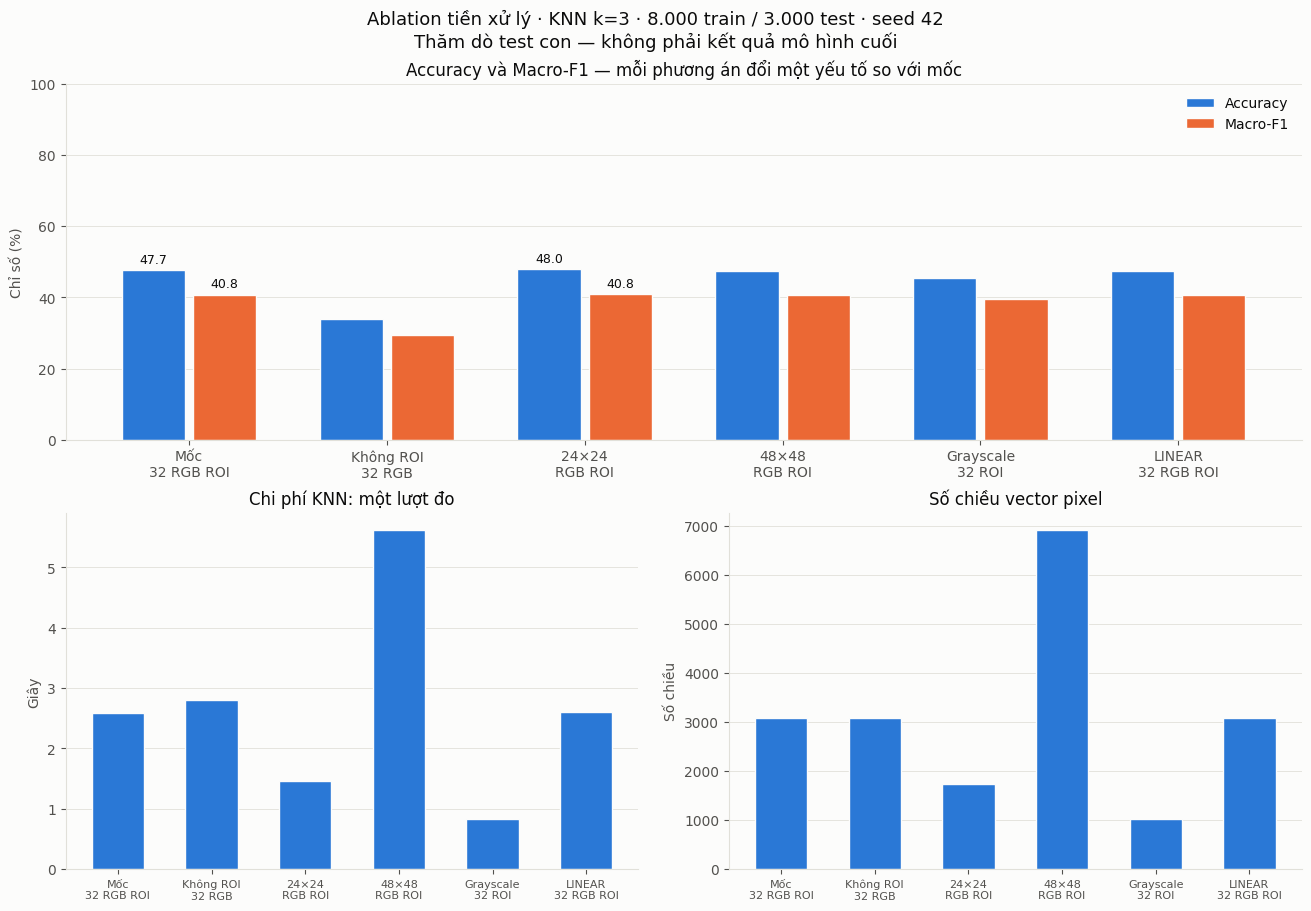

,Phương án,Số chiều,Accuracy,Macro-F1,Fit+predict (s),Δ Accuracy (đpt),Δ Macro-F1 (đpt)
Variant,,,,,,,
baseline,ROI · 32 · RGB · AREA,3072,0.4767,0.4076,2.5875,0.0000,0.0000
no_roi,Không ROI · 32 · RGB,3072,0.3403,0.2949,2.7952,-13.6333,-11.2719
size24,ROI · 24 · RGB,1728,0.4800,0.4084,1.4561,0.3333,0.0789
size48,ROI · 48 · RGB,6912,0.4747,0.4055,5.6184,-0.2000,-0.2161
grayscale,ROI · 32 · Gray,1024,0.4547,0.3955,0.8307,-2.2000,-1.2064
linear,ROI · 32 · RGB · LINEAR,3072,0.4737,0.4060,2.6067,-0.3000,-0.1659


### NHẬN XÉT định lượng từ phiên chạy

Mốc: Accuracy **47.67%**, Macro-F1 **40.76%**, **3,072 chiều**.
- **Không ROI · 32 · RGB**: Accuracy 34.03%, Macro-F1 29.49%; ΔAccuracy **-13.63 đpt**, ΔMacro-F1 **-11.27 đpt** so với mốc.
- **ROI · 24 · RGB**: Accuracy 48.00%, Macro-F1 40.84%; ΔAccuracy **+0.33 đpt**, ΔMacro-F1 **+0.08 đpt** so với mốc.
- **ROI · 48 · RGB**: Accuracy 47.47%, Macro-F1 40.55%; ΔAccuracy **-0.20 đpt**, ΔMacro-F1 **-0.22 đpt** so với mốc.
- **ROI · 32 · Gray**: Accuracy 45.47%, Macro-F1 39.55%; ΔAccuracy **-2.20 đpt**, ΔMacro-F1 **-1.21 đpt** so với mốc.
- **ROI · 32 · RGB · LINEAR**: Accuracy 47.37%, Macro-F1 40.60%; ΔAccuracy **-0.30 đpt**, ΔMacro-F1 **-0.17 đpt** so với mốc.

In [5]:
# Hai màu đã chạy validator; nhãn, legend và CSV bổ sung cho nhận biết màu.
COLORS = {"Accuracy": "#2a78d6", "Macro-F1": "#eb6834"}
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
PRINT_TEXTURE = False
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "legend.frameon": False,
    }
)
short_names = [
    "Mốc\n32 RGB ROI",
    "Không ROI\n32 RGB",
    "24×24\nRGB ROI",
    "48×48\nRGB ROI",
    "Grayscale\n32 ROI",
    "LINEAR\n32 RGB ROI",
]
x = np.arange(len(results))
fig = plt.figure(figsize=(13, 9), layout="constrained")
grid = fig.add_gridspec(2, 2)
score_ax = fig.add_subplot(grid[0, :])
for metric, offset, hatch in (
    ("Accuracy", -0.18, "/"),
    ("Macro-F1", 0.18, "\\"),
):
    values = results[metric].to_numpy() * 100
    score_ax.bar(
        x + offset,
        values,
        width=0.32,
        color=COLORS[metric],
        label=metric,
        edgecolor=SURFACE,
        linewidth=1,
        hatch=hatch if PRINT_TEXTURE else None,
    )
    # Chỉ gắn nhãn mốc và cực đại, toàn bộ số nằm ở bảng bên dưới.
    for index in sorted({0, int(np.argmax(values))}):
        score_ax.annotate(
            f"{values[index]:.1f}",
            (x[index] + offset, values[index]),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color=INK,
        )
score_ax.set(
    xticks=x,
    xticklabels=short_names,
    ylim=(0, 100),
    ylabel="Chỉ số (%)",
    title="Accuracy và Macro-F1 — mỗi phương án đổi một yếu tố so với mốc",
)
score_ax.legend(loc="upper right")
score_ax.grid(axis="y")
for axis, column, title, ylabel in (
    (
        fig.add_subplot(grid[1, 0]),
        "Fit+predict (s)",
        "Chi phí KNN: một lượt đo",
        "Giây",
    ),
    (
        fig.add_subplot(grid[1, 1]),
        "Số chiều",
        "Số chiều vector pixel",
        "Số chiều",
    ),
):
    axis.bar(
        x,
        results[column],
        width=0.56,
        color=COLORS["Accuracy"],
        edgecolor=SURFACE,
        linewidth=1,
        hatch="/" if PRINT_TEXTURE else None,
    )
    axis.set(xticks=x, xticklabels=short_names, title=title, ylabel=ylabel)
    axis.tick_params(axis="x", labelsize=8)
    axis.grid(axis="y")
fig.suptitle(
    "Ablation tiền xử lý · KNN k=3 · 8.000 train / 3.000 test · seed 42\n"
    "Thăm dò test con — không phải kết quả mô hình cuối",
    fontsize=13,
)
fig.savefig(FIGURES / "eda_ablation.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
display(
    results[
        [
            "Phương án",
            "Số chiều",
            "Accuracy",
            "Macro-F1",
            "Fit+predict (s)",
            "Δ Accuracy (đpt)",
            "Δ Macro-F1 (đpt)",
        ]
    ].round(4)
)

base = results.loc["baseline"]
lines = [
    "### NHẬN XÉT định lượng từ phiên chạy",
    "",
    f"Mốc: Accuracy **{base['Accuracy'] * 100:.2f}%**, "
    f"Macro-F1 **{base['Macro-F1'] * 100:.2f}%**, **{int(base['Số chiều']):,} chiều**.",
]
for key in results.index[1:]:
    row = results.loc[key]
    lines.append(
        f"- **{row['Phương án']}**: Accuracy {row['Accuracy'] * 100:.2f}%, "
        f"Macro-F1 {row['Macro-F1'] * 100:.2f}%; "
        f"ΔAccuracy **{row['Δ Accuracy (đpt)']:+.2f} đpt**, "
        f"ΔMacro-F1 **{row['Δ Macro-F1 (đpt)']:+.2f} đpt** so với mốc."
    )
display(Markdown("\n".join(lines)))

**NHẬN XÉT — số liệu từ cùng mẫu 8.000 train / 3.000 test, seed 42:**

| Phương án | Số chiều | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| **Mốc: ROI, 32×32, RGB, AREA** | 3.072 | **47,67%** | **40,76%** |
| Không crop ROI | 3.072 | 34,03% | 29,49% |
| ROI, 24×24, RGB | 1.728 | 48,00% | 40,84% |
| ROI, 48×48, RGB | 6.912 | 47,47% | 40,55% |
| ROI, 32×32, grayscale | 1.024 | 45,47% | 39,55% |
| ROI, 32×32, RGB, LINEAR | 3.072 | 47,37% | 40,60% |

- **Crop ROI:** mốc cao hơn không crop **13,63 đpt Accuracy / 11,27 đpt Macro-F1**. Loại nền và căn vùng biển là giải thích phù hợp với KNN pixel, vốn rất nhạy với vị trí; chưa chứng minh ROI luôn có lợi với mọi mô hình/đầu vào.
- **Kích thước:** 24×24 nhỉnh hơn mốc **0,33 đpt Accuracy / 0,08 đpt Macro-F1**, giảm **43,75% số chiều**. Làm mượt khi thu nhỏ có thể giảm nhiễu, nhưng cũng mất chi tiết chữ số; chênh lệch nhỏ chưa có kiểm định nên **không tuyên bố thắng có ý nghĩa thống kê**. Đây là cấu hình đáng xác nhận bằng CV theo track trên train. 48×48 có **2,25 lần số chiều** nhưng thấp hơn mốc **0,20 / 0,22 đpt**, không có bằng chứng lợi ích trong thăm dò này.
- **Màu:** RGB cao hơn grayscale **2,20 đpt Accuracy / 1,21 đpt Macro-F1**. Màu hỗ trợ phân biệt nhóm biển; vẫn cần nhớ RGB có 3 lần số chiều nên phép so sánh thay cả thông tin màu lẫn hình học khoảng cách.
- **Nội suy:** LINEAR thấp hơn AREA **0,30 đpt Accuracy / 0,17 đpt Macro-F1**; khác biệt rất nhỏ, không đủ khẳng định AREA tối ưu cho mọi kích thước. Dùng AREA khi thu nhỏ là lựa chọn có cơ sở, nhưng phóng to không khôi phục chi tiết gốc.

Thời gian **fit+predict** nằm trong bảng thực thi/CSV ngay trên, tách khỏi đọc ảnh và nén cache. Chỉ đo một lượt, không diễn giải thành tốc độ bảo đảm. Các giải thích về nhiễu/màu/vị trí là cơ chế khả dĩ, không phải chứng minh nhân quả.

## 5. Quyết định bàn giao và kiểm tra cuối

**MỤC ĐÍCH:** Đối chiếu cấu hình mốc với các chỉ số đo được, nêu rõ phương án đáng xác nhận tiếp mà không chọn cấu hình tự động theo test. Kiểm tra bảng, dự đoán và các file đầu ra.

In [6]:
from src import config as current_config

assert current_config.IMAGE_SIZE == (32, 32) and current_config.USE_ROI is True
assert len(results) == 6 and len(manifest) == TRAIN_SIZE + TEST_SIZE
assert len(prediction_table) == TEST_SIZE
for metric in ("Accuracy", "Macro-F1"):
    assert results[metric].between(0, 1).all()
assert results["Fit+predict (s)"].gt(0).all()
assert results["Số chiều"].to_list() == [3072, 3072, 1728, 6912, 1024, 3072]
for key in results.index:
    predicted = prediction_table[key].to_numpy()
    assert (
        accuracy_score(labels["Test"], predicted)
        == results.loc[key, "Accuracy"]
    )
    assert (
        f1_score(
            labels["Test"],
            predicted,
            labels=np.arange(43),
            average="macro",
            zero_division=0,
        )
        == results.loc[key, "Macro-F1"]
    )

better = results.drop(index="baseline").loc[
    lambda frame: frame["Macro-F1"].gt(results.loc["baseline", "Macro-F1"])
]
if better.empty:
    print("Không có biến thể Macro-F1 cao hơn mốc trên mẫu này.")
else:
    print("CẢNH BÁO: mốc không cao nhất trên test con; KHÔNG tự đổi config.")
    display(better[["Phương án", "Accuracy", "Macro-F1", "Δ Macro-F1 (đpt)"]])
print(
    "Cấu hình bàn giao giữ nguyên: ROI=True, 32×32, RGB, INTER_AREA, float32/255."
)
print(
    "Đề xuất xác nhận các lựa chọn bằng CV theo track trên train, không tuning test."
)
for path in (
    TABLES / "ablation_preprocessing.csv",
    FIGURES / "eda_ablation.png",
    TABLES / "ablation_sample_manifest.csv",
    TABLES / "ablation_predictions.csv",
):
    assert path.is_file()
    print(path.relative_to(ROOT))

CẢNH BÁO: mốc không cao nhất trên test con; KHÔNG tự đổi config.


,Phương án,Accuracy,Macro-F1,Δ Macro-F1 (đpt)
Variant,,,,
size24,ROI · 24 · RGB,0.48,0.408401,0.078881


Cấu hình bàn giao giữ nguyên: ROI=True, 32×32, RGB, INTER_AREA, float32/255.
Đề xuất xác nhận các lựa chọn bằng CV theo track trên train, không tuning test.
report\tables\ablation_preprocessing.csv
report\figures\eda_ablation.png
report\tables\ablation_sample_manifest.csv
report\tables\ablation_predictions.csv


**NHẬN XÉT — quyết định tích hợp:** Giữ **32×32, ROI=True, RGB, INTER_AREA, float32/255** để tương thích hợp đồng đã bàn giao; không tuyên bố đây là tối ưu toàn cục. RGB giữ thông tin màu cho cả pixel và HOG, ROI giảm nền, 32×32 là mức cân bằng chi phí/chi tiết đã thống nhất trước khi xem thí nghiệm này. Nếu biến thể có điểm cao hơn, số liệu là lý do để **đề xuất xác nhận bằng CV theo track trên train**, không tự chọn theo test. Những lựa chọn cuối cùng của mô hình thuộc thành viên mô hình.

**Hạn chế cần đưa vào báo cáo:** Chỉ 8.000/3.000 ảnh, một seed, một mô hình k=3 cố định; không có đánh giá độ bất định hoặc nhiều lần đo thời gian. Test con đã dùng cho thăm dò nên không gọi là holdout hoàn toàn mù. Tăng kích thước không tạo lại chi tiết đã mất từ ảnh gốc; độ sáng/mờ chưa được sửa. Thay kênh màu còn đổi số chiều. Không kiểm tra tương tác giữa ROI/kích thước/màu/nội suy. Cache không hash từng file ảnh, cần xóa cache nếu thay ảnh. Không có StandardScaler/PCA/augmentation ở thí nghiệm này.